# CICIDS2017: does a log transform (and a wider LSTM) help the deep models?

An exploratory experiment, not part of the main grid. On CICIDS2017 the plain Decision Tree (macro F1 0.9725) and Random Forest (0.965) clearly beat the best deep models (LSTM 0.854, CNN 0.782), even though this is the biggest dataset. One likely reason is the input scaling: the CICIDS features (durations, byte counts, rates) are extremely heavy-tailed, and `StandardScaler` squashes most values near zero while a few outliers become huge. Trees are not affected by that, neural networks are.

## What this notebook does

1. **Rebuilds the same data** as `CICIDS2017_Preprocessing.ipynb` (same cleaning, same labels, same seed, same 80/20 split, so the same rows), with one change: before standard scaling, every feature goes through a **signed log transform**, `sign(x) * log(1 + |x|)`. (Plain `log1p` would fail on the few features that can be negative, such as the -1 flag values.) If `cicids2017_grouped.npz` is in the folder, it checks that the new split is identical to it.
2. **Trains three models on the transformed data**, each with the baseline recipe (no class weights, no search, so there is nothing to tune on the test set):
   - **CNN**, the baseline CNN (64 filters, kernel 3, 64 dense units, learning rate 0.001);
   - **LSTM (window 10)**, the baseline LSTM with 64 units;
   - **LSTM (window 10), 256 units**, the same but wider, to test whether the 64-unit model was too small for 2 million rows.
3. **Compares them** with the existing baseline runs (standard scaling) and the Decision Tree and Random Forest, from the JSON files in `results/`.

Reading the result: the CNN and the 64-unit LSTM, compared with their old baselines, show the effect of the log transform alone. The 256-unit LSTM compared with the 64-unit one (both on log data) shows the effect of width alone. Decision Tree and Random Forest results do not change with this transform (trees only care about the order of values), so their numbers from the main grid are the right comparison.

## Before running

- Put the eight CICIDS2017 CSV files where `DATA_DIR` points (same as for the preprocessing notebook).
- Keep `results/CICIDS2017_CNN.json`, `results/CICIDS2017_LSTM_window.json`, `results/CICIDS2017_Decision_Tree.json` and `results/CICIDS2017_Random_Forest.json` in place for the final comparison (it skips any that are missing).
- Needs roughly 4 GB of free RAM for the data step, as in the preprocessing notebook. Time: the data step takes a few minutes; on the machine that produced the earlier JSONs, expect the CNN to take a few minutes and the 64-unit LSTM about 15 minutes, with the 256-unit LSTM longer (a rough guess: 25 to 40 minutes). Set the `RUN_...` flags in the first cell to skip any of them. Each result is saved as soon as it finishes.

## How to report it

Whichever way it comes out, report it as it is: a single run per model, with the settings fixed in advance. If the log transform closes most of the gap to the trees, say that the heavy-tailed features were the problem. If it doesn't, say it was tried and did not help.

## Settings

In [5]:
import gc
import glob
import json
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support, f1_score)

import keras
from keras import layers
from keras.callbacks import EarlyStopping
import tensorflow as tf
print("GPUs visible:", tf.config.list_physical_devices("GPU"))

# Which experiments to run
RUN_CNN = True
RUN_LSTM_64 = True
RUN_LSTM_256 = True

# Training settings (the same as the baseline runs in CICIDS2017_CNN.ipynb and CICIDS2017_LSTM.ipynb)
BATCH_SIZE = 1024
EPOCHS = 50
PATIENCE = 5
WINDOW = 10
DATASET_NAME = "CICIDS2017"
BASELINE_NPZ = "cicids2017_grouped.npz"   # optional: if present, the new split is checked against it

GPUs visible: []


## 1. Rebuild the data (same steps as the preprocessing notebook)

The next five cells are the preprocessing notebook's own cells (find the files, load, clean, label, split), unchanged. Only the scaling step differs.

In [6]:
import gc
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

DATA_DIR = "."            # the folder with the eight CICIDS2017 CSVs (sub-folders are searched too)
LABEL_SCHEME = "grouped"  # "grouped" = 8 classes (recommended), "raw" = all 15 original labels
TEST_SIZE = 0.2
TRAIN_FRACTION = 1.0      # 1.0 = keep the whole training set. Below 1.0 keeps that fraction of each
                          # class (at least 30 rows per class), for faster deep learning runs.
SEED = 0

# Finds the eight files by name, in time order (Monday to Friday). It ignores upper/lower case and
# whether the name has "." or "_" before "pcap_ISCX" (both spellings exist), and it searches
# sub-folders too, because zip files often unpack into a folder inside a folder.
KEYS = ["monday", "tuesday", "wednesday",
        "thursday-workinghours-morning", "thursday-workinghours-afternoon",
        "friday-workinghours-morning", "friday-workinghours-afternoon-portscan",
        "friday-workinghours-afternoon-ddos"]

found = glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
FILES, missing = [], []
for key in KEYS:
    hits = sorted(p for p in found if key in os.path.basename(p).lower())
    if hits:
        FILES.append(hits[0])
    else:
        missing.append(key)

if missing:
    print("Looked in:", os.path.abspath(DATA_DIR))
    print("CSV files found there:", [os.path.basename(p) for p in found] or "none")
    raise FileNotFoundError(f"No file found for: {missing}. Set DATA_DIR to the folder that contains the CICIDS2017 CSVs.")

print("Using these files:")
for p in FILES:
    print("  ", p)

Using these files:
   .\Monday-WorkingHours.pcap_ISCX.csv
   .\Tuesday-WorkingHours.pcap_ISCX.csv
   .\Wednesday-workingHours.pcap_ISCX.csv
   .\Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
   .\Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
   .\Friday-WorkingHours-Morning.pcap_ISCX.csv
   .\Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
   .\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


In [7]:
frames = []
for path in FILES:
    name = os.path.basename(path)
    header = pd.read_csv(path, nrows=0, encoding="latin-1").columns
    frame = pd.read_csv(path, dtype={c: "float32" for c in header[:-1]}, encoding="latin-1")
    frame.columns = [c.strip() for c in frame.columns]   # the original names have leading spaces
    frames.append(frame)
    print(f"{name}: {len(frame):,} rows")

df = pd.concat(frames, ignore_index=True)
del frames
gc.collect()
print(f"\nTotal: {df.shape[0]:,} rows, {df.shape[1] - 1} features + label")

Monday-WorkingHours.pcap_ISCX.csv: 529,918 rows
Tuesday-WorkingHours.pcap_ISCX.csv: 445,909 rows
Wednesday-workingHours.pcap_ISCX.csv: 692,703 rows
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: 170,366 rows
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: 288,602 rows
Friday-WorkingHours-Morning.pcap_ISCX.csv: 191,033 rows
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: 286,467 rows
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: 225,745 rows

Total: 2,830,743 rows, 78 features + label


In [8]:
# Repair the corrupted dash in the web attack labels ("Web Attack <?> Brute Force")
df["Label"] = df["Label"].str.replace(r"[^\x20-\x7e]+", "-", regex=True).str.strip()

# Drop the redundant duplicate column
assert (df["Fwd Header Length"] == df["Fwd Header Length.1"]).all()
df = df.drop(columns="Fwd Header Length.1")
feature_cols = [c for c in df.columns if c != "Label"]

# Drop rows with NaN or infinite values
values = df[feature_cols].to_numpy()
bad_rows = ~np.isfinite(values).all(axis=1)
del values
print(f"Dropping {bad_rows.sum():,} rows with NaN/infinite values")
df = df[~bad_rows].reset_index(drop=True)

# Drop exact duplicate rows (features + label), compared through a 64-bit hash of each row
is_duplicate = pd.util.hash_pandas_object(df, index=False).duplicated().to_numpy()
print(f"Dropping {is_duplicate.sum():,} duplicate rows")
df = df[~is_duplicate].reset_index(drop=True)

# Drop constant columns
constant_cols = [c for c in feature_cols if df[c].nunique() == 1]
print(f"Dropping {len(constant_cols)} constant columns: {constant_cols}")
df = df.drop(columns=constant_cols)
feature_cols = [c for c in df.columns if c != "Label"]

print(f"\nRows after cleaning: {len(df):,} (2,497,980 with the standard files) | features: {len(feature_cols)}")
gc.collect()

Dropping 2,867 rows with NaN/infinite values
Dropping 329,896 duplicate rows
Dropping 8 constant columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Rows after cleaning: 2,497,980 (2,497,980 with the standard files) | features: 69


0

In [9]:
GROUPS = {
    "BENIGN": "Benign",
    "DoS Hulk": "DoS", "DoS GoldenEye": "DoS", "DoS slowloris": "DoS", "DoS Slowhttptest": "DoS",
    "DDoS": "DDoS",
    "PortScan": "PortScan",
    "FTP-Patator": "Brute Force", "SSH-Patator": "Brute Force",
    "Web Attack - Brute Force": "Web Attack", "Web Attack - XSS": "Web Attack",
    "Web Attack - Sql Injection": "Web Attack",
    "Bot": "Bot",
    "Infiltration": "Infiltration/Heartbleed", "Heartbleed": "Infiltration/Heartbleed",
}
GROUP_ORDER = ["Benign", "DoS", "DDoS", "PortScan", "Brute Force", "Web Attack", "Bot",
               "Infiltration/Heartbleed"]

if LABEL_SCHEME == "grouped":
    target = df["Label"].map(GROUPS)
    class_names = GROUP_ORDER
elif LABEL_SCHEME == "raw":
    target = df["Label"]
    class_names = sorted(target.unique())
else:
    raise ValueError("LABEL_SCHEME must be 'grouped' or 'raw'")

y = pd.Categorical(target, categories=class_names).codes.astype("int64")
if (y < 0).any():
    raise ValueError("Unmapped labels: " + str(sorted(set(df['Label'][y < 0]))))
n_classes = len(class_names)
print(pd.Series(np.bincount(y), index=class_names).to_string())

Benign                     2072254
DoS                         193730
DDoS                        128014
PortScan                     90694
Brute Force                   9150
Web Attack                    2143
Bot                           1948
Infiltration/Heartbleed         47


In [10]:
idx_train, idx_test = train_test_split(np.arange(len(y)), test_size=TEST_SIZE,
                                       stratify=y, random_state=SEED)
idx_train.sort()
idx_test.sort()

if TRAIN_FRACTION < 1.0:
    rng = np.random.default_rng(SEED)
    keep = []
    for c in range(n_classes):
        members = idx_train[y[idx_train] == c]
        k = max(min(30, len(members)), int(round(TRAIN_FRACTION * len(members))))
        keep.append(rng.choice(members, k, replace=False))
    idx_train = np.sort(np.concatenate(keep))
    print(f"Training set reduced to {TRAIN_FRACTION:.0%} of each class (min 30 rows per class)")

X_all = df[feature_cols].to_numpy(dtype="float32")
del df
gc.collect()
X_train, y_train = X_all[idx_train], y[idx_train]
X_test, y_test = X_all[idx_test], y[idx_test]
del X_all
gc.collect()
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1998384, 69) | Test: (499596, 69)


## 2. Signed log transform, then standard scaling

The transform is applied to the training and test rows alike, one row at a time, so it uses nothing from the test set. The scaler is fitted on the (transformed) training set only.

In [11]:
CHUNK = 200_000

def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))

for X in (X_train, X_test):
    for start in range(0, len(X), CHUNK):
        X[start:start + CHUNK] = signed_log(X[start:start + CHUNK].astype("float64")).astype("float32")

scaler = StandardScaler()
for start in range(0, len(X_train), CHUNK):
    scaler.partial_fit(X_train[start:start + CHUNK].astype("float64"))
for X in (X_train, X_test):
    for start in range(0, len(X), CHUNK):
        X[start:start + CHUNK] = scaler.transform(X[start:start + CHUNK].astype("float64")).astype("float32")

print("Largest absolute scaled value in train:", float(np.abs(X_train).max()),
      "(with plain standard scaling this is in the hundreds or thousands)")

# Check that this is the same split as the baseline runs used
if os.path.exists(BASELINE_NPZ):
    ref = np.load(BASELINE_NPZ)
    same = (np.array_equal(ref["y_train"], y_train) and np.array_equal(ref["y_test"], y_test))
    print("Same rows and labels as", BASELINE_NPZ, ":", same)
    assert same, "The split differs from the one the baselines used. Check DATA_DIR and the settings."
    del ref
else:
    print(f"{BASELINE_NPZ} not found, so the split was not checked. Expected train 1,998,384 / test 499,596 rows.")
print("Train:", X_train.shape, "| Test:", X_test.shape)

Largest absolute scaled value in train: 179.52993774414062 (with plain standard scaling this is in the hundreds or thousands)
Same rows and labels as cicids2017_grouped.npz : True
Train: (1998384, 69) | Test: (499596, 69)


In [12]:
def evaluate(model_name, config, y_true, y_pred, class_names):
    """Print the metrics, classification report and confusion matrix; return the numbers."""
    labels = np.arange(len(class_names))
    acc = accuracy_score(y_true, y_pred)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average="macro", zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)

    print(f"{model_name} ({DATASET_NAME}, {config})")
    print(f"Accuracy {acc:.4f} | Macro precision {macro_p:.3f} | Macro recall {macro_r:.3f} | "
          f"Macro F1 {macro_f1:.3f} | Weighted F1 {weighted_f1:.3f}\n")
    print(classification_report(y_true, y_pred, labels=labels, target_names=class_names,
                                zero_division=0))

    fig, ax = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=labels),
                           display_labels=class_names).plot(ax=ax, xticks_rotation=45,
                                                           cmap="Blues", colorbar=False)
    ax.set_title(f"{model_name} confusion matrix ({DATASET_NAME}, {config})")
    fig.tight_layout()
    plt.show()

    return {"accuracy": acc, "macro_precision": macro_p, "macro_recall": macro_r,
            "macro_f1": macro_f1, "weighted_f1": weighted_f1,
            "report": classification_report(y_true, y_pred, labels=labels,
                                            target_names=class_names, zero_division=0,
                                            output_dict=True)}

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(history.history["accuracy"], label="train")
    axes[0].plot(history.history["val_accuracy"], label="validation")
    axes[0].set_title(f"{title}: accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(history.history["loss"], label="train")
    axes[1].plot(history.history["val_loss"], label="validation")
    axes[1].set_title(f"{title}: loss"); axes[1].set_xlabel("epoch"); axes[1].legend()
    fig.tight_layout(); plt.show()

## 3. Models

The same sequence builder as the LSTM notebooks. With `window=None` it gives the CNN its (features, 1) input; with a window it gives the LSTM the current row plus the 9 rows before it. The validation split is the same stratified 10% (seed 0) as in the baselines.

In [13]:
class RowSequence(keras.utils.Sequence):
    """Yields (X, y[, sample_weight]) batches.
    window=None -> X is (batch, features, 1); window=W -> X is (batch, W, features).
    `indices` picks which rows are samples; a window always looks back at the real previous rows
    of X, even when only a subset of rows is used for training."""

    def __init__(self, X, y, indices, window=None, batch_size=256, shuffle=False,
                 weights=None, seed=SEED):
        super().__init__()
        self.X, self.y, self.weights = X, y, weights
        self.indices = np.array(indices)
        self.window, self.batch_size, self.shuffle = window, batch_size, shuffle
        self.rng = np.random.default_rng(seed)
        if shuffle:
            self.rng.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, i):
        idx = self.indices[i * self.batch_size:(i + 1) * self.batch_size]
        if self.window is None:
            xb = self.X[idx][:, :, None]
        else:
            offsets = np.arange(-self.window + 1, 1)
            xb = self.X[np.clip(idx[:, None] + offsets[None, :], 0, None)]
        yb = self.y[idx]
        if self.weights is None:
            return xb, yb
        return xb, yb, self.weights[yb]

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indices)

In [14]:
tr_idx, val_idx = train_test_split(np.arange(len(X_train)), test_size=0.1,
                                   stratify=y_train, random_state=SEED)
n_features = X_train.shape[1]
test_all = np.arange(len(X_test))
results = {}

def build_cnn():
    return keras.Sequential([
        keras.Input(shape=(n_features, 1)),
        layers.Conv1D(64, kernel_size=3, activation="relu", padding="same"),
        layers.MaxPooling1D(pool_size=2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ])

def build_lstm(units):
    def build():
        return keras.Sequential([
            keras.Input(shape=(WINDOW, n_features)),
            layers.LSTM(units),
            layers.Dense(n_classes, activation="softmax"),
        ])
    return build

def run(key, model_name, config, build, window):
    keras.utils.set_random_seed(SEED)
    train_seq = RowSequence(X_train, y_train, tr_idx, window, BATCH_SIZE, shuffle=True)
    val_seq = RowSequence(X_train, y_train, val_idx, window, 1024)
    test_seq = RowSequence(X_test, y_test, test_all, window, 1024)
    model = build()
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    early_stop = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(train_seq, validation_data=val_seq, epochs=EPOCHS,
                        callbacks=[early_stop], verbose=2)
    secs = time.perf_counter() - start
    print(f"Trained in {secs:.1f}s ({len(history.history['loss'])} epochs)")
    plot_history(history, config)
    y_pred = model.predict(test_seq, verbose=0).argmax(axis=1)
    result = evaluate(model_name, config, y_test, y_pred, class_names)
    result["train_seconds"] = secs
    result["epochs"] = len(history.history["loss"])
    results[key] = result
    os.makedirs("results", exist_ok=True)
    json.dump(results, open("results/CICIDS2017_logtransform.json", "w"), indent=1, default=float)
    del model
    keras.backend.clear_session()
    gc.collect()

## 4. CNN on log-transformed data

Epoch 1/50
1757/1757 - 18s - 10ms/step - accuracy: 0.9901 - loss: 0.0389 - val_accuracy: 0.9972 - val_loss: 0.0109
Epoch 2/50
1757/1757 - 17s - 10ms/step - accuracy: 0.9975 - loss: 0.0096 - val_accuracy: 0.9972 - val_loss: 0.0092
Epoch 3/50
1757/1757 - 17s - 10ms/step - accuracy: 0.9977 - loss: 0.0084 - val_accuracy: 0.9980 - val_loss: 0.0077
Epoch 4/50
1757/1757 - 16s - 9ms/step - accuracy: 0.9979 - loss: 0.0078 - val_accuracy: 0.9980 - val_loss: 0.0071
Epoch 5/50
1757/1757 - 16s - 9ms/step - accuracy: 0.9980 - loss: 0.0074 - val_accuracy: 0.9976 - val_loss: 0.0081
Epoch 6/50
1757/1757 - 16s - 9ms/step - accuracy: 0.9980 - loss: 0.0070 - val_accuracy: 0.9981 - val_loss: 0.0069
Epoch 7/50
1757/1757 - 16s - 9ms/step - accuracy: 0.9981 - loss: 0.0068 - val_accuracy: 0.9981 - val_loss: 0.0065
Epoch 8/50
1757/1757 - 16s - 9ms/step - accuracy: 0.9981 - loss: 0.0065 - val_accuracy: 0.9982 - val_loss: 0.0073
Epoch 9/50
1757/1757 - 16s - 9ms/step - accuracy: 0.9982 - loss: 0.0065 - val_accurac

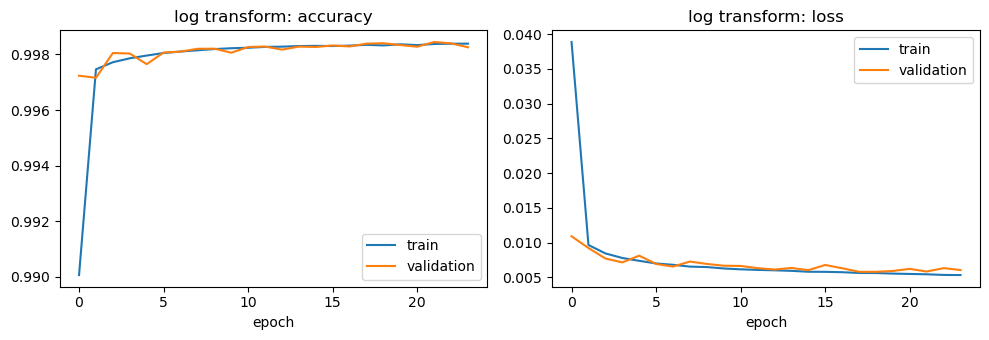

CNN (CICIDS2017, log transform)
Accuracy 0.9985 | Macro precision 0.954 | Macro recall 0.915 | Macro F1 0.912 | Weighted F1 0.998

                         precision    recall  f1-score   support

                 Benign       1.00      1.00      1.00    414451
                    DoS       1.00      1.00      1.00     38746
                   DDoS       1.00      1.00      1.00     25603
               PortScan       0.99      1.00      0.99     18139
            Brute Force       0.99      1.00      0.99      1830
             Web Attack       0.97      0.99      0.98       428
                    Bot       0.99      0.35      0.51       390
Infiltration/Heartbleed       0.69      1.00      0.82         9

               accuracy                           1.00    499596
              macro avg       0.95      0.92      0.91    499596
           weighted avg       1.00      1.00      1.00    499596



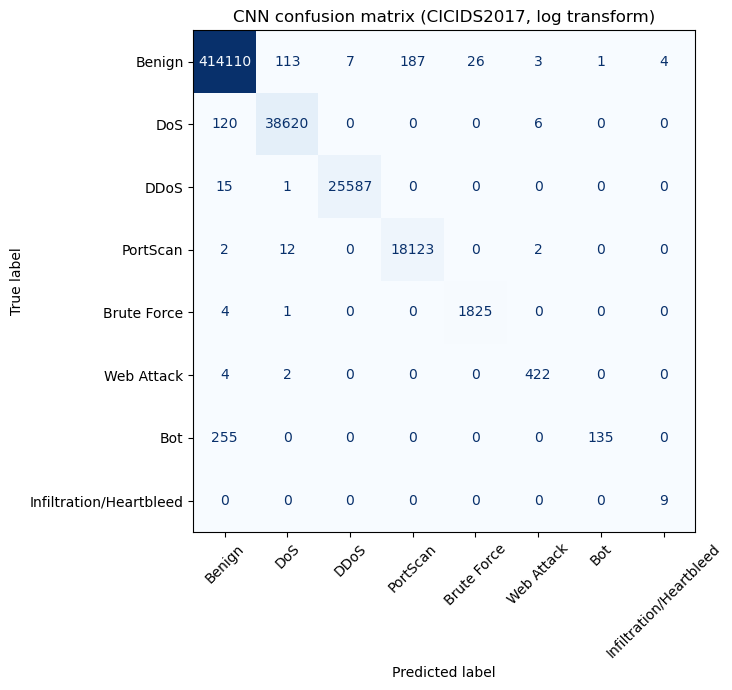

In [15]:
if RUN_CNN:
    run("cnn_log", "CNN", "log transform", build_cnn, window=None)
else:
    print("Skipped")

## 5. LSTM (window 10, 64 units) on log-transformed data

Epoch 1/50
1757/1757 - 25s - 14ms/step - accuracy: 0.9903 - loss: 0.0449 - val_accuracy: 0.9974 - val_loss: 0.0110
Epoch 2/50
1757/1757 - 23s - 13ms/step - accuracy: 0.9980 - loss: 0.0082 - val_accuracy: 0.9983 - val_loss: 0.0066
Epoch 3/50
1757/1757 - 23s - 13ms/step - accuracy: 0.9986 - loss: 0.0055 - val_accuracy: 0.9986 - val_loss: 0.0051
Epoch 4/50
1757/1757 - 23s - 13ms/step - accuracy: 0.9988 - loss: 0.0045 - val_accuracy: 0.9988 - val_loss: 0.0044
Epoch 5/50
1757/1757 - 24s - 13ms/step - accuracy: 0.9989 - loss: 0.0039 - val_accuracy: 0.9988 - val_loss: 0.0045
Epoch 6/50
1757/1757 - 24s - 14ms/step - accuracy: 0.9990 - loss: 0.0036 - val_accuracy: 0.9989 - val_loss: 0.0040
Epoch 7/50
1757/1757 - 24s - 13ms/step - accuracy: 0.9991 - loss: 0.0033 - val_accuracy: 0.9990 - val_loss: 0.0038
Epoch 8/50
1757/1757 - 23s - 13ms/step - accuracy: 0.9991 - loss: 0.0031 - val_accuracy: 0.9990 - val_loss: 0.0038
Epoch 9/50
1757/1757 - 23s - 13ms/step - accuracy: 0.9992 - loss: 0.0030 - val_a

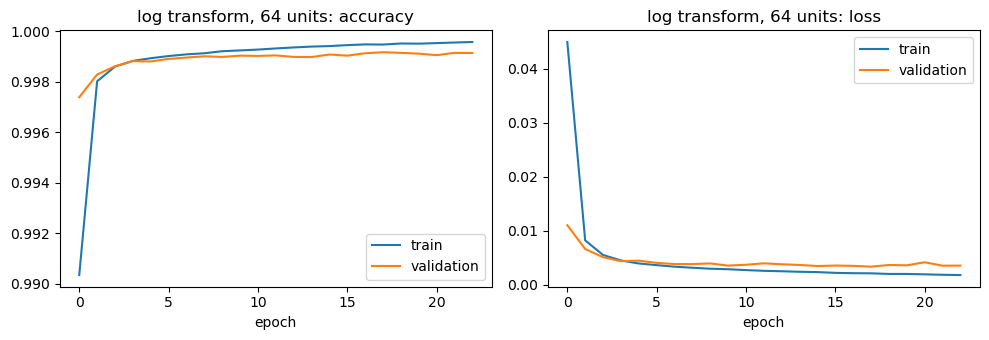

LSTM (window) (CICIDS2017, log transform, 64 units)
Accuracy 0.9988 | Macro precision 0.950 | Macro recall 0.910 | Macro F1 0.927 | Weighted F1 0.999

                         precision    recall  f1-score   support

                 Benign       1.00      1.00      1.00    414451
                    DoS       1.00      1.00      1.00     38746
                   DDoS       1.00      1.00      1.00     25603
               PortScan       0.99      0.99      0.99     18139
            Brute Force       0.99      0.99      0.99      1830
             Web Attack       0.94      0.97      0.96       428
                    Bot       0.80      0.55      0.65       390
Infiltration/Heartbleed       0.88      0.78      0.82         9

               accuracy                           1.00    499596
              macro avg       0.95      0.91      0.93    499596
           weighted avg       1.00      1.00      1.00    499596



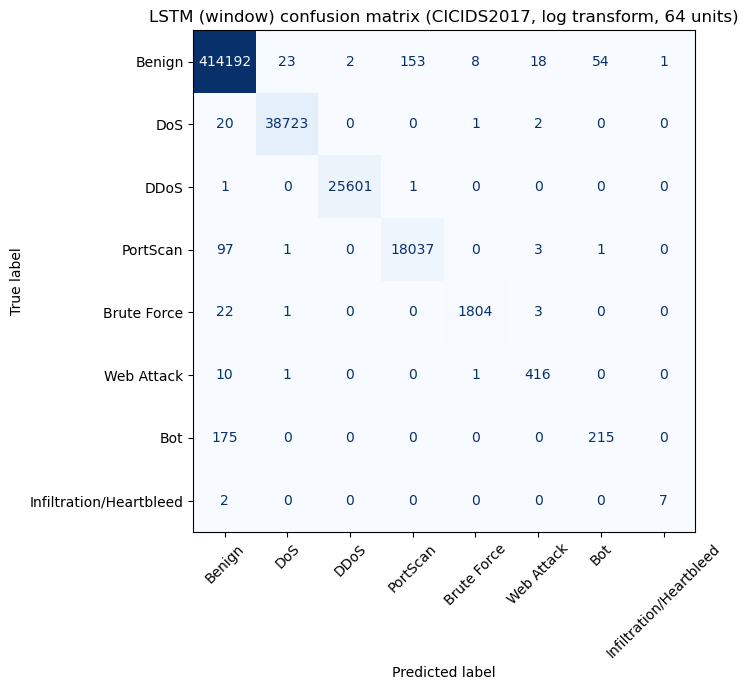

In [16]:
if RUN_LSTM_64:
    run("lstm_log_64", "LSTM (window)", "log transform, 64 units", build_lstm(64), window=WINDOW)
else:
    print("Skipped")

## 6. LSTM (window 10, 256 units) on log-transformed data

Epoch 1/50
1757/1757 - 95s - 54ms/step - accuracy: 0.9941 - loss: 0.0247 - val_accuracy: 0.9982 - val_loss: 0.0076
Epoch 2/50
1757/1757 - 94s - 53ms/step - accuracy: 0.9983 - loss: 0.0063 - val_accuracy: 0.9983 - val_loss: 0.0060
Epoch 3/50
1757/1757 - 94s - 53ms/step - accuracy: 0.9988 - loss: 0.0046 - val_accuracy: 0.9987 - val_loss: 0.0045
Epoch 4/50
1757/1757 - 95s - 54ms/step - accuracy: 0.9990 - loss: 0.0038 - val_accuracy: 0.9988 - val_loss: 0.0040
Epoch 5/50
1757/1757 - 95s - 54ms/step - accuracy: 0.9991 - loss: 0.0034 - val_accuracy: 0.9988 - val_loss: 0.0042
Epoch 6/50
1757/1757 - 95s - 54ms/step - accuracy: 0.9992 - loss: 0.0031 - val_accuracy: 0.9989 - val_loss: 0.0039
Epoch 7/50
1757/1757 - 96s - 55ms/step - accuracy: 0.9992 - loss: 0.0028 - val_accuracy: 0.9990 - val_loss: 0.0036
Epoch 8/50
1757/1757 - 96s - 55ms/step - accuracy: 0.9994 - loss: 0.0025 - val_accuracy: 0.9991 - val_loss: 0.0038
Epoch 9/50
1757/1757 - 94s - 54ms/step - accuracy: 0.9994 - loss: 0.0024 - val_a

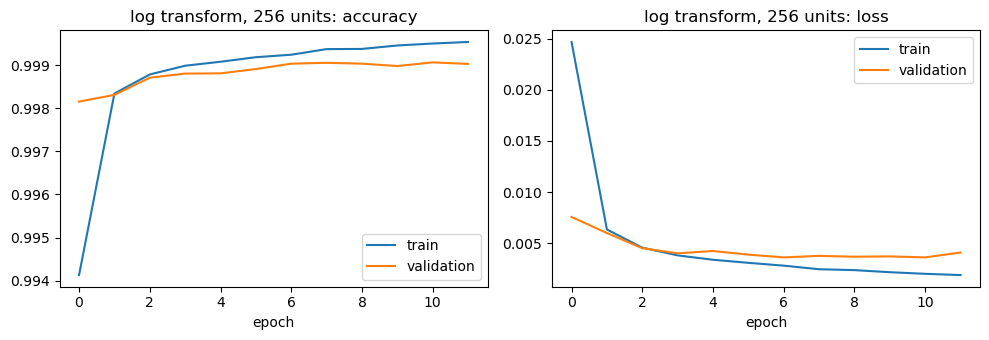

LSTM (window) (CICIDS2017, log transform, 256 units)
Accuracy 0.9988 | Macro precision 0.973 | Macro recall 0.881 | Macro F1 0.915 | Weighted F1 0.999

                         precision    recall  f1-score   support

                 Benign       1.00      1.00      1.00    414451
                    DoS       1.00      1.00      1.00     38746
                   DDoS       1.00      1.00      1.00     25603
               PortScan       0.99      1.00      0.99     18139
            Brute Force       1.00      0.98      0.99      1830
             Web Attack       0.95      0.96      0.96       428
                    Bot       0.85      0.55      0.67       390
Infiltration/Heartbleed       1.00      0.56      0.71         9

               accuracy                           1.00    499596
              macro avg       0.97      0.88      0.92    499596
           weighted avg       1.00      1.00      1.00    499596



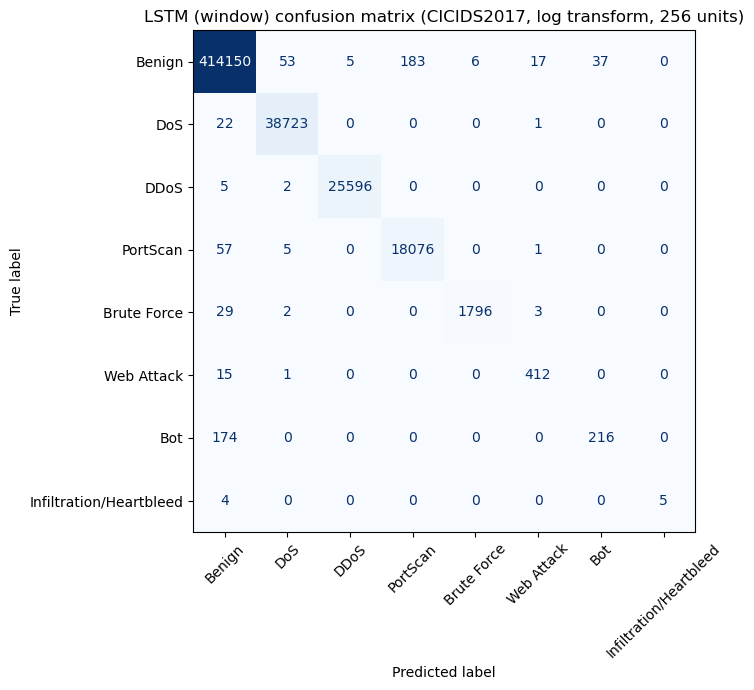

In [17]:
if RUN_LSTM_256:
    run("lstm_log_256", "LSTM (window)", "log transform, 256 units", build_lstm(256), window=WINDOW)
else:
    print("Skipped")

## 7. Comparison

The new runs next to the existing baselines (standard scaling) and the tree models. Files that are not in `results/` are skipped. The results are also saved in `results/CICIDS2017_logtransform.json`: send me that file.

Missing: results/CICIDS2017_CNN.json
Missing: results/CICIDS2017_LSTM_window.json


,Accuracy,Macro precision,Macro recall,Macro F1,Train time (s)
Decision Tree,0.9985,0.9712,0.9738,0.9725,75.9303
Random Forest,0.9986,0.9817,0.9505,0.9650,67.4001
CNN (log transform),0.9985,0.9538,0.9155,0.9116,387.5805
"LSTM window, 64 units (log transform)",0.9988,0.9496,0.9100,0.9266,528.9039
"LSTM window, 256 units (log transform)",0.9988,0.9734,0.8810,0.9153,1135.6776


,Decision Tree,Random Forest,CNN (log transform),"LSTM window, 64 units (log transform)","LSTM window, 256 units (log transform)"
Benign,0.999,0.999,0.999,0.999,0.999
DoS,0.998,0.998,0.997,0.999,0.999
DDoS,1.000,1.000,1.000,1.000,1.000
PortScan,0.987,0.990,0.994,0.993,0.993
Brute Force,0.998,1.000,0.992,0.990,0.989
Web Attack,0.981,0.988,0.980,0.956,0.956
Bot,0.817,0.804,0.513,0.652,0.672
Infiltration/Heartbleed,1.000,0.941,0.818,0.824,0.714


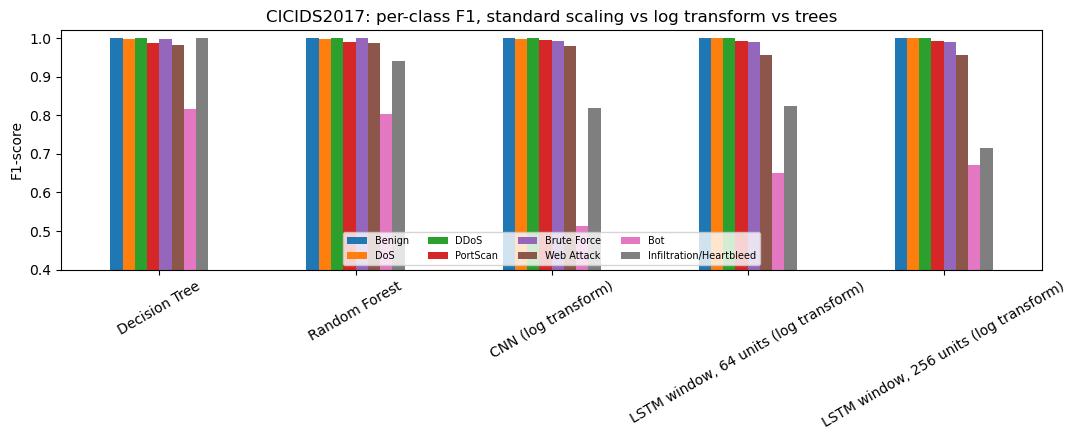

In [19]:
sources = [
    ("Decision Tree", "results/CICIDS2017_Decision_Tree.json", "baseline"),
    ("Random Forest", "results/CICIDS2017_Random_Forest.json", "baseline"),
    ("CNN (standard scaling)", "results/CICIDS2017_CNN.json", "baseline"),
    ("LSTM window, 64 units (standard scaling)", "results/CICIDS2017_LSTM_window.json", "baseline"),
]
allr = {}
for name, path, key in sources:
    if os.path.exists(path):
        allr[name] = json.load(open(path))[key]
    else:
        print("Missing:", path)
labels = {"cnn_log": "CNN (log transform)", "lstm_log_64": "LSTM window, 64 units (log transform)",
          "lstm_log_256": "LSTM window, 256 units (log transform)"}
for k, name in labels.items():
    if k in results:
        allr[name] = results[k]

summary = pd.DataFrame({n: {"Accuracy": r["accuracy"], "Macro precision": r["macro_precision"],
                            "Macro recall": r["macro_recall"], "Macro F1": r["macro_f1"],
                            "Train time (s)": r.get("train_seconds", float("nan"))}
                        for n, r in allr.items()}).T
display(summary.round(4))

per_class = pd.DataFrame({n: [r["report"][c]["f1-score"] for c in class_names] for n, r in allr.items()},
                         index=class_names)
display(per_class.round(3))
ax = per_class.T.plot.bar(figsize=(11, 4.5), rot=30)
ax.set_ylabel("F1-score")
ax.set_ylim(0.4, 1.02)
ax.set_title("CICIDS2017: per-class F1, standard scaling vs log transform vs trees")
ax.legend(loc="lower center", ncol=4, fontsize=7)
plt.tight_layout()
plt.show()